# Missing-value handling and feature comparison

Compare three logistic regression baselines on the **same five grouped folds**:
text only; text + keyword; text + keyword + location. Missing metadata is an
explicit category; no tweets are dropped and labels are not modified. Target 1
is the positive (disaster) class. Only train.csv is used; test.csv is untouched.

In [1]:
from pathlib import Path
from disaster_tweets.paths import PROJECT_ROOT, RAW_DATA_DIR, PROCESSED_DATA_DIR, EDA_REPORTS_DIR, BASELINE_REPORTS_DIR
import hashlib
import json
import time
import warnings

import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, display
from sklearn.exceptions import ConvergenceWarning
from sklearn.metrics import (accuracy_score, confusion_matrix, f1_score,
                             precision_score, recall_score, ConfusionMatrixDisplay)
from sklearn.model_selection import StratifiedGroupKFold

from disaster_tweets.model_pipeline import make_model
from disaster_tweets.preprocessing import clean_metadata, normalize_for_grouping, read_training_csv

ROOT = PROJECT_ROOT
OUT = BASELINE_REPORTS_DIR
OUT.mkdir(exist_ok=True)
SEED = 42
source_hash = hashlib.sha256((RAW_DATA_DIR / 'train.csv').read_bytes()).hexdigest()
raw = read_training_csv(RAW_DATA_DIR / 'train.csv')
train_processed = clean_metadata(raw)
assert train_processed['target'].isin([0, 1]).all()
assert train_processed['text'].str.strip().ne('').all()
pd.testing.assert_frame_equal(train_processed[['id', 'text', 'target']], raw[['id', 'text', 'target']])
assert train_processed.notna().all().all()
train_processed.to_csv(PROCESSED_DATA_DIR / 'train_processed.csv', index=False)
print(f'Preserved all {len(train_processed):,} rows; no missing metadata remains.')
display(train_processed.head())

Preserved all 7,613 rows; no missing metadata remains.


,id,keyword,location,text,target
0,1,__MISSING__,__MISSING__,Our Deeds are the Reason of this #earthquake M...,1
1,4,__MISSING__,__MISSING__,Forest fire near La Ronge Sask. Canada,1
2,5,__MISSING__,__MISSING__,All residents asked to 'shelter in place' are ...,1
3,6,__MISSING__,__MISSING__,"13,000 people receive #wildfires evacuation or...",1
4,7,__MISSING__,__MISSING__,Just got sent this photo from Ruby #Alaska as ...,1


## 1. Fixed validation folds with duplicate protection

StratifiedGroupKFold (five folds, shuffled, seed 42) groups conservative
normalized text: HTML unescape, Unicode NFKC, case folding, and collapsed
whitespace. Every row is validated once; no such group crosses a training/
validation boundary. Conflicting labels stay unchanged in the same group.
Near-duplicate templates and events can still overlap, so this is not an
event-held-out evaluation. IDs and row order are not model features.

In [2]:
X = train_processed[['text', 'keyword', 'location']]
y = train_processed['target'].to_numpy()
groups = train_processed['text'].map(normalize_for_grouping).to_numpy()
splitter = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
splits = list(splitter.split(X, y, groups))
fold_ids = np.full(len(X), -1, dtype=int)
fold_audit_rows = []
for fold, (fit_idx, valid_idx) in enumerate(splits, start=1):
    overlap = set(groups[fit_idx]) & set(groups[valid_idx])
    assert not overlap
    assert (fold_ids[valid_idx] == -1).all()
    fold_ids[valid_idx] = fold
    fold_audit_rows.append({'fold': fold, 'train_rows': len(fit_idx), 'validation_rows': len(valid_idx),
                            'train_disaster_rate': float(y[fit_idx].mean()),
                            'validation_disaster_rate': float(y[valid_idx].mean()),
                            'overlapping_normalized_text_groups': len(overlap)})
assert (fold_ids > 0).all()
fold_audit = pd.DataFrame(fold_audit_rows)
fold_audit.to_csv(OUT / 'fold_audit.csv', index=False)
pd.DataFrame({'id': train_processed['id'], 'fold': fold_ids}).to_csv(OUT / 'fold_assignments.csv', index=False)
display(fold_audit.round(4))

,fold,train_rows,validation_rows,train_disaster_rate,validation_disaster_rate,overlapping_normalized_text_groups
0,1,6088,1525,0.4297,0.4295,0
1,2,6092,1521,0.4296,0.4300,0
2,3,6090,1523,0.4297,0.4294,0
3,4,6091,1522,0.4297,0.4297,0
4,5,6091,1522,0.4297,0.4297,0


## 2. Identical text models; add metadata one field at a time

Each model combines word TF-IDF (1–2 grams, min_df=2, max_features=30,000)
and character-within-word TF-IDF (3–5 grams, min_df=2, max_features=50,000).
Default L2 TF-IDF normalization and sublinear term frequencies are used.
Text is lowercased by TF-IDF; raw text remains intact in the processed CSV.
We preserve stopwords/negation and do not strip URLs or hashtag words.

Keyword is one-hot encoded. Location is one-hot encoded with values occurring
fewer than five times in a training fold grouped as infrequent. Unseen
categories are ignored. No target encoding is used. These are fixed choices,
not tuned settings. All vocabularies, IDF values, categories, and rare-category
grouping are learned **inside each training fold** using a pipeline.

LogisticRegression uses C=1, L2 regularization, liblinear, no class weighting,
max_iter=1000, and threshold 0.5. Feature block weights are all 1. This compares
these specific encodings; it does not establish that location is always useful
or useless. We retain conflicting-label records for this initial comparison.

In [3]:
MODEL_SPECS = {
    'text_only': ('Text only', []),
    'text_keyword': ('Text + keyword', ['keyword']),
    'text_keyword_location': ('Text + keyword + location', ['keyword', 'location']),
}

def score_predictions(truth, predicted):
    return {'f1': float(f1_score(truth, predicted, zero_division=0)),
            'precision': float(precision_score(truth, predicted, zero_division=0)),
            'recall': float(recall_score(truth, predicted, zero_division=0)),
            'accuracy': float(accuracy_score(truth, predicted))}

oof = pd.DataFrame({'id': train_processed['id'], 'target': y, 'fold': fold_ids})
fold_results = []
model_summary_rows = []
for model_name, (label, metadata) in MODEL_SPECS.items():
    predicted = np.full(len(X), -1, dtype=int)
    probabilities = np.full(len(X), np.nan)
    started = time.perf_counter()
    for fold, (fit_idx, valid_idx) in enumerate(splits, start=1):
        model = make_model(metadata)
        # Treat convergence warnings as failures instead of silently scoring an unfinished fit.
        with warnings.catch_warnings():
            warnings.simplefilter('error', ConvergenceWarning)
            model.fit(X.iloc[fit_idx], y[fit_idx])
        prob = model.predict_proba(X.iloc[valid_idx])[:, 1]
        pred = (prob >= 0.5).astype(int)
        predicted[valid_idx] = pred
        probabilities[valid_idx] = prob
        scores = score_predictions(y[valid_idx], pred)
        fold_results.append({'model': model_name, 'label': label, 'fold': fold, **scores})
        print(f'{label} | fold {fold}: F1={scores["f1"]:.4f}', flush=True)
    assert (predicted >= 0).all() and np.isfinite(probabilities).all()
    oof[f'{model_name}_prediction'] = predicted
    oof[f'{model_name}_probability'] = probabilities
    fold_frame = pd.DataFrame([r for r in fold_results if r['model'] == model_name])
    model_summary_rows.append({'model': model_name, 'label': label,
                                'mean_fold_f1': float(fold_frame.f1.mean()),
                                'std_fold_f1': float(fold_frame.f1.std(ddof=1)),
                                **{f'oof_{k}': v for k, v in score_predictions(y, predicted).items()},
                                'elapsed_seconds': time.perf_counter() - started})

fold_results = pd.DataFrame(fold_results)
model_summary = pd.DataFrame(model_summary_rows)
model_summary['delta_oof_f1_vs_text'] = model_summary['oof_f1'] - model_summary.iloc[0]['oof_f1']
fold_results.to_csv(OUT / 'fold_metrics.csv', index=False)
model_summary.to_csv(OUT / 'model_comparison.csv', index=False)
oof.to_csv(OUT / 'oof_predictions.csv', index=False)
display(model_summary.drop(columns='elapsed_seconds').round(4))

Text only | fold 1: F1=0.7560


Text only | fold 2: F1=0.7662


Text only | fold 3: F1=0.7566


Text only | fold 4: F1=0.7873


Text only | fold 5: F1=0.7589


...

Text + keyword + location | fold 2: F1=0.7671


Text + keyword + location | fold 3: F1=0.7717


Text + keyword + location | fold 4: F1=0.7853


Text + keyword + location | fold 5: F1=0.7581


,model,label,mean_fold_f1,std_fold_f1,oof_f1,oof_precision,oof_recall,oof_accuracy,delta_oof_f1_vs_text
0,text_only,Text only,0.7650,0.0131,0.7650,0.8291,0.7102,0.8126,0.0000
1,text_keyword,Text + keyword,0.7699,0.0074,0.7699,0.8166,0.7282,0.8130,0.0049
2,text_keyword_location,Text + keyword + location,0.7703,0.0098,0.7703,0.8115,0.7331,0.8122,0.0053


## 3. Comparison and error inspection

OOF means out-of-fold: each prediction comes from a model that did not train
on that row or its conservative duplicate group. Mean fold F1 and pooled OOF
F1 differ because F1 is nonlinear. Error bars below show fold standard
deviations, not confidence intervals. Scores share folds and are correlated.
Inspect changes in precision and recall as well as F1. Small differences do
not establish a reliable winner; this comparison is not an independent final
test set after selecting features.

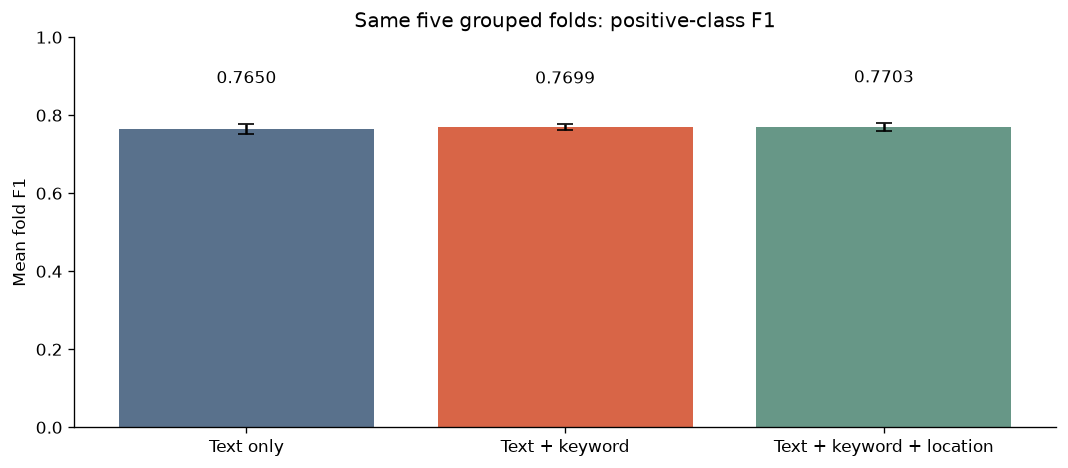

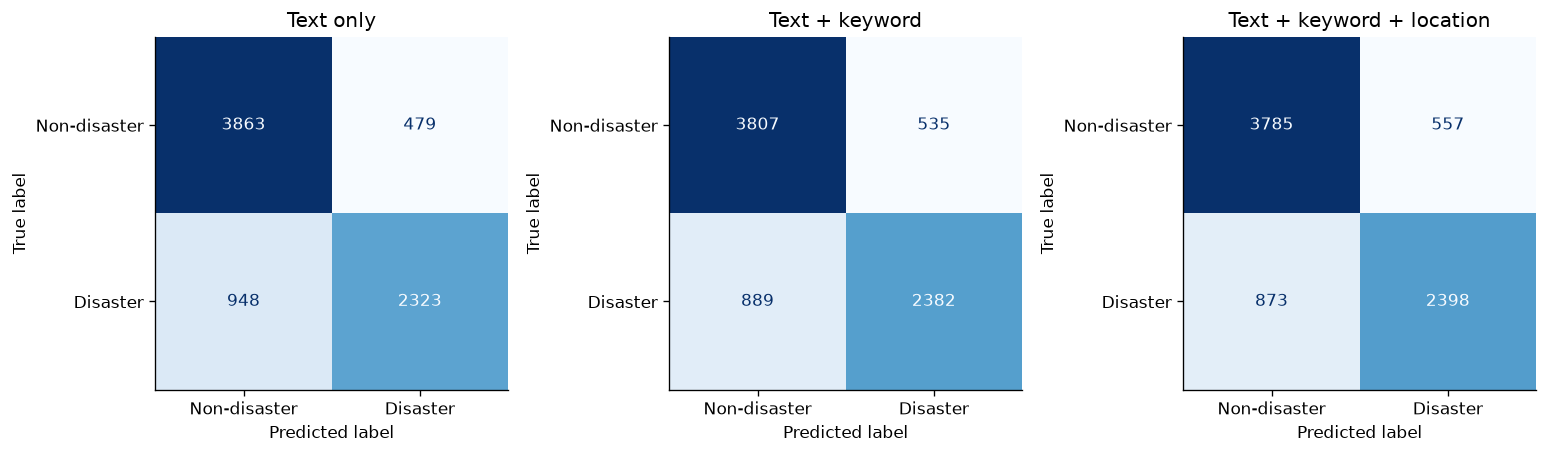

In [4]:
plt.rcParams.update({'figure.dpi': 120, 'axes.spines.top': False, 'axes.spines.right': False})
fig, ax = plt.subplots(figsize=(9, 4))
bars = ax.bar(model_summary['label'], model_summary['mean_fold_f1'],
              yerr=model_summary['std_fold_f1'], capsize=5,
              color=['#59718C', '#D86547', '#679787'])
ax.bar_label(bars, fmt='%.4f', padding=22)
ax.set(title='Same five grouped folds: positive-class F1', ylabel='Mean fold F1', ylim=(0, 1))
fig.tight_layout()
fig.savefig(OUT / 'model_comparison.png', bbox_inches='tight')
display(Image(filename=str(OUT / 'model_comparison.png')))
plt.close(fig)

fig, axes = plt.subplots(1, 3, figsize=(13, 4))
confusion_matrices = {}
for (name, (label, _)), ax in zip(MODEL_SPECS.items(), axes):
    matrix = confusion_matrix(y, oof[f'{name}_prediction'], labels=[0, 1])
    confusion_matrices[name] = matrix.tolist()
    ConfusionMatrixDisplay(matrix, display_labels=['Non-disaster', 'Disaster']).plot(
        ax=ax, colorbar=False, cmap='Blues', values_format='d')
    ax.set_title(label)
fig.tight_layout()
fig.savefig(OUT / 'confusion_matrices.png', bbox_inches='tight')
display(Image(filename=str(OUT / 'confusion_matrices.png')))
plt.close(fig)

error_frames = []
for name in MODEL_SPECS:
    wrong = oof[f'{name}_prediction'].ne(oof['target'])
    errors = train_processed.loc[wrong, ['id', 'keyword', 'location', 'text', 'target']].copy()
    errors['model'] = name
    errors['fold'] = fold_ids[wrong]
    errors['prediction'] = oof.loc[wrong, f'{name}_prediction'].to_numpy()
    errors['probability_disaster'] = oof.loc[wrong, f'{name}_probability'].to_numpy()
    error_frames.append(errors)
pd.concat(error_frames, ignore_index=True).to_csv(OUT / 'validation_errors.csv', index=False)

## 4. Exported findings

The baseline report records all three models and their fixed settings. Use it
to choose the next experiment, rather than interpreting the highest score as a
confirmed improvement. The processed dataset is suitable for text-only models
and for metadata experiments; `__MISSING__` is an explicit categorical value.

In [5]:
def md_table(frame):
    rows = [[f'{v:.4f}' if isinstance(v, (float, np.floating)) else str(v) for v in row]
            for row in frame.itertuples(index=False, name=None)]
    return '\n'.join(['| ' + ' | '.join(map(str, frame.columns)) + ' |',
                      '| ' + ' | '.join(['---'] * len(frame.columns)) + ' |'] +
                     ['| ' + ' | '.join(row) + ' |' for row in rows])

text_score = model_summary.iloc[0].oof_f1
keyword_score = model_summary.iloc[1].oof_f1
location_score = model_summary.iloc[2].oof_f1
report_columns = ['label', 'mean_fold_f1', 'std_fold_f1', 'oof_f1', 'oof_precision',
                   'oof_recall', 'oof_accuracy', 'delta_oof_f1_vs_text']
report = f'''# Missing values and feature comparison

## Applied policy

- Preserve all {len(train_processed):,} training rows and keep raw text, IDs, and targets unchanged.
- Trim keyword/location strings; replace empty, whitespace-only, or null values with `__MISSING__`.
- Keyword: {int(train_processed.keyword.eq('__MISSING__').sum())} explicit missing markers. Location: {int(train_processed.location.eq('__MISSING__').sum())} markers (including one whitespace-only source value).
- Save the result as `../../data/processed/train_processed.csv`. This replaces unknown information with a marker, not a guessed real value. The raw CSV is unchanged.

## Three-model comparison

{md_table(model_summary[report_columns])}

All F1, precision, and recall values refer to the positive disaster class. OOF scores pool predictions for all rows; each row is predicted exactly once by a model trained outside its validation fold. Mean fold F1 is the average of five separate F1 scores. Fold standard deviation is not a confidence interval.

Adding keyword changes pooled OOF F1 from **{text_score:.4f} to {keyword_score:.4f}** ({keyword_score-text_score:+.4f}). Adding location on top of keyword changes it to **{location_score:.4f}** ({location_score-keyword_score:+.4f} versus keyword).

![Five-fold comparison](model_comparison.png)

![Pooled OOF confusion matrices](confusion_matrices.png)

## Validation design and settings

- Five fixed StratifiedGroupKFold folds, shuffled, seed {SEED}. Conservative normalized text groups never cross train/validation boundaries. Grouping applies HTML unescape, Unicode NFKC, case folding, and whitespace collapse. Class stratification is approximate because groups are indivisible.
- The same folds, classifier, threshold, and text feature settings are used in all three experiments. IDs and row position are excluded from inputs.
- Word TF-IDF: 1–2 grams, min_df=2, max_features=30,000. Character TF-IDF: char_wb 3–5 grams, min_df=2, max_features=50,000. Both use lowercase, sublinear TF, and default L2 normalization. No stopword removal or URL stripping is applied.
- Keyword is one-hot encoded. Location is one-hot encoded with min_frequency=5 in each training fold. Unknown categories are ignored. Feature block weights are all 1.
- Logistic regression: C=1, L2 penalty, liblinear, max_iter=1000, no class weighting, seed {SEED}. Decision threshold is fixed at 0.5; no parameter or threshold tuning is performed.
- Vocabulary, IDF, metadata categories, and rare-location grouping are fitted on training-fold data only. Missing-value handling is a deterministic transformation with no learned statistics.
- Conflicting labels are retained without modification and grouped together. Near duplicates, event/topic overlap, and label noise remain possible. This is not a time- or event-held-out test, and feature selection on these folds is not independent final evaluation.

## How to use these results

Keep the text-only score as the reference. Treat any metadata gain as provisional and check it with another split or nested evaluation before increasing pipeline complexity. Compare the paired fold metrics and the false positives/negatives, rather than relying only on the largest aggregate score. Raw location values describe supplied profile metadata and need not be the location of a disaster.

## Artifacts and reproduction

- `model_comparison.csv`: all three scores; `fold_metrics.csv`: fold-level metrics.
- `fold_assignments.csv` and `fold_audit.csv`: fixed validation membership and zero duplicate-group overlap.
- `oof_predictions.csv`: prediction and probability for each row/model; `validation_errors.csv`: errors with text and metadata for review.
- `metrics.json`: machine-readable results and source hash.
- Run `python scripts/baseline.py` from the project root, or `python scripts/build_notebooks.py baseline` to rebuild the executed `../../notebooks/02_baseline.ipynb` and HTML export.

No final model is fitted on all rows and no test-set predictions are generated in this comparison. Source SHA-256: `{source_hash}`.
'''
(OUT / 'report.md').write_text(report, encoding='utf-8')
settings = {'seed': SEED, 'n_splits': 5, 'threshold': 0.5, 'classifier': 'LogisticRegression',
            'C': 1.0, 'solver': 'liblinear', 'max_iter': 1000,
            'word_ngram_range': [1, 2], 'word_max_features': 30_000,
            'char_ngram_range': [3, 5], 'char_max_features': 50_000,
            'min_df': 2, 'location_min_frequency': 5}
metrics = {'source': 'data/raw/train.csv', 'source_sha256': source_hash, 'rows': len(train_processed),
           'settings': settings, 'fold_audit': fold_audit.to_dict(orient='records'),
           'models': model_summary.to_dict(orient='records'), 'confusion_matrices': confusion_matrices}
(OUT / 'metrics.json').write_text(json.dumps(metrics, indent=2), encoding='utf-8')
assert hashlib.sha256((RAW_DATA_DIR / 'train.csv').read_bytes()).hexdigest() == source_hash
print('Completed three models × five grouped folds. Reports and predictions are in reports/baseline/.')
display(model_summary[report_columns].round(4))

Completed three models × five grouped folds. Reports and predictions are in reports/baseline/.


,label,mean_fold_f1,std_fold_f1,oof_f1,oof_precision,oof_recall,oof_accuracy,delta_oof_f1_vs_text
0,Text only,0.7650,0.0131,0.7650,0.8291,0.7102,0.8126,0.0000
1,Text + keyword,0.7699,0.0074,0.7699,0.8166,0.7282,0.8130,0.0049
2,Text + keyword + location,0.7703,0.0098,0.7703,0.8115,0.7331,0.8122,0.0053
